In [34]:
def plot_traces_v_ax(
    ax,
    cube_3d,
    cube_3d2=None,
    z_index=0,
    title=None,
    borde=5,
    n_traces=10,
    spread=None,                 # controla apertura lateral; si None usa Nx/20
    ref_kwargs=None,             # estilo para referencia
    pred_kwargs=None,            # estilo para cube_3d2
    invert_time_axis=True,
    show_grid=True,
    legend=True,
    delta_t = 0.001
):
    """
    Versión "para subplot" de plot_traces_v: dibuja en un Axes (ax) ya existente.

    cube_3d: shape (t, x, z) según tu docstring, PERO tu indexado usa cube_3d[:, Rz, Rx]
             (o sea: tiempo, z, x). Esta función mantiene tu misma convención.
    """
    if ref_kwargs is None:
        ref_kwargs = dict(color="black", linewidth=1.0)
    if pred_kwargs is None:
        pred_kwargs = dict(color="red", linestyle="dashed", alpha=0.7, linewidth=1.0)

    def get_traces(Rx, Rz, cube):
        Nt = cube.shape[0]
        T = np.zeros((Rx.shape[0], Nt), dtype=float)
        for i in range(Rx.shape[0]):
            T[i] = cube[:, Rz[i], Rx[i]]
        return T

    # Dimensiones
    Nt, Nz, Nx = cube_3d.shape
    if cube_3d2 is not None:
        assert cube_3d2.shape == cube_3d.shape, "cube_3d2 debe tener la misma forma que cube_3d"

    # Selección de trazas
    borde = int(max(0, borde))
    if Nx - 2 * borde <= 0:
        raise ValueError(f"borde={borde} es demasiado grande para Nx={Nx}")

    n_traces = int(max(1, n_traces))
    Rx_subset = np.linspace(borde, Nx - borde - 1, n_traces, dtype=int)
    Rz_subset = np.full(Rx_subset.shape[0], z_index, dtype=int)

    T1 = get_traces(Rx_subset, Rz_subset, cube_3d)
    T2 = get_traces(Rx_subset, Rz_subset, cube_3d2) if cube_3d2 is not None else None

    t = np.arange(Nt)*delta_t#*1000 # *1000 para mostrar en ms

    # Factor de escala lateral
    if spread is None:
        spread = Nx / 20.0
    spread = float(spread)

    # Limpiar el axes (opcional; si no quieres, borra esta línea)
    ax.cla()

    # Plot referencia
    for i in range(T1.shape[0]):
        tr = T1[i]
        denom = np.max(np.abs(tr))
        scaled = (tr / denom * spread) if denom > 0 else np.zeros_like(tr)
        offset = Rx_subset[i]
        label = "Analytical" if i == 0 else None
        ax.plot(offset + scaled, t, label=label, **ref_kwargs)

    # Plot comparación
    if T2 is not None:
        for i in range(T2.shape[0]):
            tr = T2[i]
            denom = np.max(np.abs(tr))
            scaled = (tr / denom * spread) if denom > 0 else np.zeros_like(tr)
            offset = Rx_subset[i]
            label = "Finite Differences" if i == 0 else None
            ax.plot(offset + scaled, t, label=label, **pred_kwargs)

    ax.set_xlabel("Receptors (x)")
    ax.set_ylabel("Time (s)")
    ax.set_title(title if title else f"Traces at z={z_index}")

    if invert_time_axis:
        ax.invert_yaxis()

    if show_grid:
        ax.grid(True, alpha=0.3)

    if legend:
        ax.legend(loc="upper right", fontsize="small")

    # Para que el eje x tenga sentido como "receptores"
    ax.set_xlim(-0.5, Nx - 0.5)
    ax.set_ylim(t.max() - delta_t, 0) if invert_time_axis else ax.set_ylim(0, t.max() - delta_t)

    return ax

def multi_plot_propagation(vel_model, ground_truth, prediction, time_1, time_2, z_index, output_file=None, n_traces=10, delta_t=0.001):
    
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    from matplotlib.colors import BoundaryNorm, ListedColormap, Normalize

    # -----------------------------
    # Estilo global (profesional)
    # -----------------------------
    plt.rcParams.update({
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "figure.titlesize": 13,
    })

    # -----------------------------
    # Datos
    # -----------------------------

    velocity_model = vel_model
    unique_vals = np.unique(vel_model)
    print(f"Unique velocity values: {unique_vals}")
    num_classes = len(unique_vals)
    base_cmap = plt.get_cmap("viridis")
    norm_cont = Normalize(vmin=1500, vmax=4500)
    colors = base_cmap(norm_cont(unique_vals))    
    cmap_velocity = ListedColormap(colors)
    
    norm = BoundaryNorm(
        boundaries=np.append(unique_vals - 0.5, unique_vals[-1] + 0.5),
        ncolors=num_classes,
    )
    
    gt1 = ground_truth[time_1]
    gt2 = ground_truth[time_2]

    pred1 = prediction[time_1]
    pred2 = prediction[time_2]

    err1 = np.abs(gt1 - pred1)
    err2 = np.abs(gt2 - pred2)
    # -----------------------------
    # Figura y Grid
    # -----------------------------
    fig = plt.figure(figsize=(14, 6), constrained_layout=False)

    gs = GridSpec(
        2, 7, figure=fig,
        width_ratios=[1, 1, 1, 0.04, 1, 0.04, 0.04]
    )

    # Subplots
    ax00 = fig.add_subplot(gs[0, 0])
    ax10 = fig.add_subplot(gs[1, 0])

    ax01 = fig.add_subplot(gs[0, 1])
    ax11 = fig.add_subplot(gs[1, 1])

    ax02 = fig.add_subplot(gs[0, 2])
    ax12 = fig.add_subplot(gs[1, 2])

    cax_seismic = fig.add_subplot(gs[:, 3])

    ax03 = fig.add_subplot(gs[0, 4])
    ax13 = fig.add_subplot(gs[1, 4])

    cax_gray = fig.add_subplot(gs[:, 5])

    # -----------------------------
    # Límites compartidos
    # -----------------------------
    #vmin = min(gt1.min(), gt2.min(), pred1.min(), pred2.min())
    vmax = 1#max(gt1.max(), gt2.max(), pred1.max(), pred2.max())
    vmin = -vmax

    # -----------------------------
    # Plots
    # -----------------------------
    im_vel = ax00.imshow(velocity_model, cmap=cmap_velocity, aspect="equal", norm=norm)
    ax00.set_title("Velocity model")

    plot_traces_v_ax(
        ax10,
        cube_3d=ground_truth,
        cube_3d2=prediction,   # o None si no quieres comparar
        z_index=z_index,             # el z que quieras
        title="Shot gather",
        borde=5,
        n_traces=n_traces,
        spread=None,           # o un número para abrir/cerrar más
        delta_t = delta_t
    )
    ax10.set_title(f"Shot gather at z={z_index} Km")

    im_gt1 = ax01.imshow(gt1, cmap="seismic", vmin=vmin, vmax=vmax, aspect="equal")
    im_gt2 = ax11.imshow(gt2, cmap="seismic", vmin=vmin, vmax=vmax, aspect="equal")

    im_pr1 = ax02.imshow(pred1, cmap="seismic", vmin=vmin, vmax=vmax, aspect="equal")
    im_pr2 = ax12.imshow(pred2, cmap="seismic", vmin=vmin, vmax=vmax, aspect="equal")

    im_er1 = ax03.imshow(err1, cmap="Greys", aspect="equal") 
    im_er2 = ax13.imshow(err2, cmap="Greys", aspect="equal")

    # -----------------------------
    # Títulos de columnas
    # -----------------------------
    ax01.set_title("Analytical")
    ax02.set_title("Finite Differences")
    ax03.set_title("Absolute Error")

    # -----------------------------
    # Colorbars
    # -----------------------------
    # Colorbar del modelo de velocidad (integrado)
    cb_vel = plt.colorbar(im_vel, ax=ax00, ticks=unique_vals,  pad=0.12)
    cb_vel.ax.invert_yaxis()
    #cb_vel = fig.colorbar(im_vel, ax=ax00, fraction=0.046, pad=0.04)
    cb_vel.set_label("Velocity (m/s)")
    cb_vel.ax.yaxis.set_label_position("left")
    
    cb_seismic = fig.colorbar(im_pr1, cax=cax_seismic)
    cb_seismic.set_label("Amplitude", labelpad=10)
    cb_seismic.ax.yaxis.set_label_position("left")
    #cb_seismic.ax.yaxis.tick_left()


    cb_gray = fig.colorbar(im_er1, cax=cax_gray)
    cb_gray.set_label("Absolute error", labelpad=10)
    cb_gray.ax.yaxis.set_label_position("left")

       
    
    fig.text(0.23, 0.75, f"t = {time_1*delta_t} (s)", rotation=90,
         va='center', ha='center', fontsize=14, fontweight='bold')
    
    fig.text(0.23, 0.28, f"t = {time_2*delta_t} (s)", rotation=90,
            va='center', ha='center', fontsize=14, fontweight='bold')
    # -----------------------------
    # Etiquetas de fila (profesional)
    # -----------------------------
    ax02.set_ylabel(f"Depth (Km)")
    ax12.set_ylabel(f"Depth (Km)")
    ax11.set_xlabel(f"offset (Km)")
    ax12.set_xlabel(f"offset (Km)")
    ax13.set_xlabel(f"offset (Km)")


    # -----------------------------
    # Limpieza visual
    # -----------------------------
    for ax in [ax00, ax01, ax02, ax03, ax10, ax11, ax12, ax13]:
        # quitar grid
        ax.grid(False)
        #Poner ticks mas pegados al grafico
        ax.tick_params(axis='both', which='both', length=0)
    # Ajustar layout
    plt.tight_layout()     
    #save pdf
    
    plt.savefig(output_file if output_file else "wave_propagation_comparison.pdf", dpi=300, bbox_inches='tight')
    plt.show()

In [1]:
import joblib
import os
import numpy as np
import sys

base_path = os.getcwd()
project_path = os.path.dirname(os.path.dirname(base_path))
print(project_path)




/home/osakatest/sebastian_guerrero/Code/DeepONet_AWP


In [14]:
sys.path.append(os.path.dirname(base_path))
reference_folder_1 = os.path.join(project_path, "data","wavefields","analytical")
reference_folder_2 = os.path.join(project_path, "data","wavefields","homogenous")

x_ref = np.load(os.path.join(project_path,"data", "vel_models","homogenous", "model_00.npy"))
y_analytical = np.load(os.path.join(reference_folder_1, "wavefield_00.npy"))

y_fd = np.load(os.path.join(reference_folder_2, "wavefield_00.npy"))

In [21]:
y_fd.shape

(7, 800, 70, 70)

In [22]:
y_analytical[0,100]

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(70, 70), dtype=float32)

Unique velocity values: [1500.]


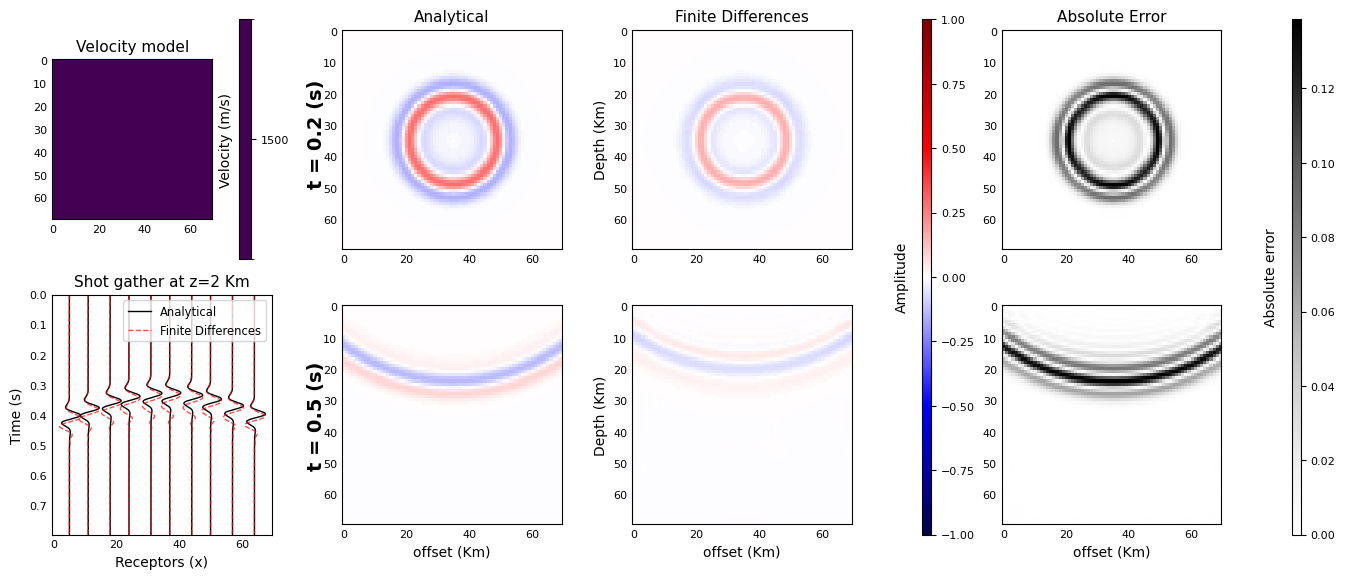

In [35]:
n=0
x_ref_n = x_ref[n,0]
y_analytical_n = y_analytical[n]
y_analytical_n = y_analytical_n/np.nanmax(y_analytical_n)
y_fd_n = y_fd[n]
y_fd_n = y_fd_n/np.max(y_fd_n)
multi_plot_propagation(x_ref_n, y_analytical_n, y_fd_n, time_1=200, time_2=500, z_index=2, output_file=None, delta_t=0.001)

In [29]:
np.nanmax(y_analytical[n])

np.float32(10.275113)

In [30]:
np.max(y_fd[n])

np.float32(20.114445)